In [1]:
import numpy as np
import pandas as pd

In [3]:
columns = ['Unit_Number', 'Time_in_cycles', 'Operational_setting-1', 'Operational_setting_2', 'Operational_setting_3'] + [f'Sensor_measurment_{i}' for i in range(1,22)]

df = pd.read_csv('data/train_FD001.txt', sep='\s+', names=columns)
df.head()

,Unit_Number,Time_in_cycles,Operational_setting-1,Operational_setting_2,Operational_setting_3,Sensor_measurment_1,Sensor_measurment_2,Sensor_measurment_3,Sensor_measurment_4,Sensor_measurment_5,...,Sensor_measurment_12,Sensor_measurment_13,Sensor_measurment_14,Sensor_measurment_15,Sensor_measurment_16,Sensor_measurment_17,Sensor_measurment_18,Sensor_measurment_19,Sensor_measurment_20,Sensor_measurment_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [4]:
df.columns = df.columns.str.strip()

In [5]:
df['RUL'] = df.groupby('Unit_Number') ['Time_in_cycles'].transform('max') - df['Time_in_cycles']
df.head()

,Unit_Number,Time_in_cycles,Operational_setting-1,Operational_setting_2,Operational_setting_3,Sensor_measurment_1,Sensor_measurment_2,Sensor_measurment_3,Sensor_measurment_4,Sensor_measurment_5,...,Sensor_measurment_13,Sensor_measurment_14,Sensor_measurment_15,Sensor_measurment_16,Sensor_measurment_17,Sensor_measurment_18,Sensor_measurment_19,Sensor_measurment_20,Sensor_measurment_21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [6]:
df.tail()

,Unit_Number,Time_in_cycles,Operational_setting-1,Operational_setting_2,Operational_setting_3,Sensor_measurment_1,Sensor_measurment_2,Sensor_measurment_3,Sensor_measurment_4,Sensor_measurment_5,...,Sensor_measurment_13,Sensor_measurment_14,Sensor_measurment_15,Sensor_measurment_16,Sensor_measurment_17,Sensor_measurment_18,Sensor_measurment_19,Sensor_measurment_20,Sensor_measurment_21,RUL
20626,100,196,-0.0004,-0.0003,100.0,518.67,643.49,1597.98,1428.63,14.62,...,2388.26,8137.60,8.4956,0.03,397,2388,100.0,38.49,22.9735,4
20627,100,197,-0.0016,-0.0005,100.0,518.67,643.54,1604.50,1433.58,14.62,...,2388.22,8136.50,8.5139,0.03,395,2388,100.0,38.30,23.1594,3
20628,100,198,0.0004,0.0000,100.0,518.67,643.42,1602.46,1428.18,14.62,...,2388.24,8141.05,8.5646,0.03,398,2388,100.0,38.44,22.9333,2
20629,100,199,-0.0011,0.0003,100.0,518.67,643.23,1605.26,1426.53,14.62,...,2388.23,8139.29,8.5389,0.03,395,2388,100.0,38.29,23.0640,1
20630,100,200,-0.0032,-0.0005,100.0,518.67,643.85,1600.38,1432.14,14.62,...,2388.26,8137.33,8.5036,0.03,396,2388,100.0,38.37,23.0522,0


In [7]:
df = df.loc[:,df.nunique() > 1]

In [8]:
X = df.drop(columns=["Unit_Number", "Time_in_cycles","RUL"])
y = df["RUL"]
X_normalized = (X-X.mean()) / X.std()

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_normalized, y, test_size = 0.2, random_state = 42)
print("Data Normalized and split complete")

Data Normalized and split complete


In [9]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

model = LinearRegression()
model.fit(X_train, y_train)
predictions = model.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, predictions))

print(f"RMSE (Root Mean Squared Error): {rmse:.2f}")
print(f"MAE (Mean Absolute Error): {rmse:.2f}")

RMSE (Root Mean Squared Error): 44.34
MAE (Mean Absolute Error): 44.34


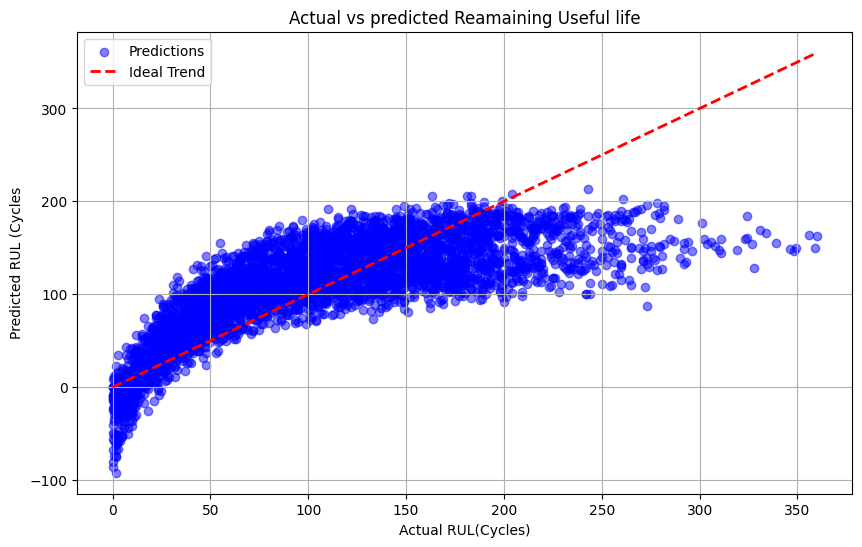

In [10]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,6))
plt.scatter(y_test, predictions, alpha = 0.5, color = 'blue', label = 'Predictions')

plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2, label = 'Ideal Trend')

plt.xlabel('Actual RUL(Cycles)')
plt.ylabel('Predicted RUL (Cycles')
plt.title('Actual vs predicted Reamaining Useful life')
plt.legend()
plt.grid(True)
plt.show()